### Find Missing Image NUmbers in between the Range

IMAGE NUMBER ANALYSIS REPORT
Directory: W:\1945_02_09#00314#US7_0067_A
Analysis Range: 3033 - 8024
Existing images: 32/4992
Missing images: 4960/4992
Completion rate: 0.64%

MISSING NUMBER RANGES:
3035-3049,3051-3052,3058-4015,4019-4028,4031-4034,4038-4042,4045-4054,4056-4058,4064-8008,8011,8015-8021


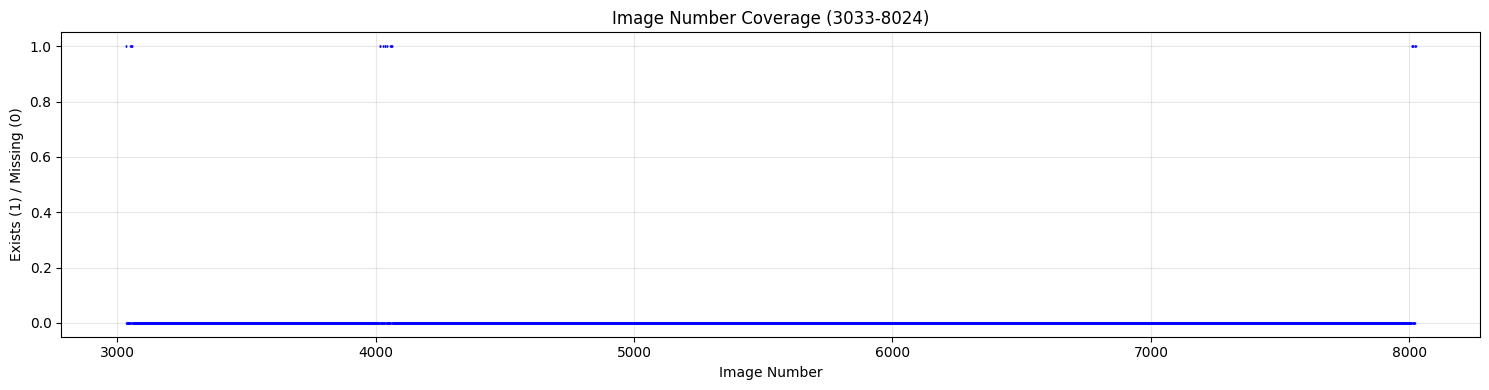


Formatted ranges only: 3035-3049,3051-3052,3058-4015,4019-4028,4031-4034,4038-4042,4045-4054,4056-4058,4064-8008,8011,8015-8021


In [1]:
import os
import re
import matplotlib.pyplot as plt
import pandas as pd

class ImageNumberAnalyzer:
    def __init__(self, path, range_start=1000, range_end=5000):
        self.path = path
        self.range_start = range_start
        self.range_end = range_end
        self.existing_numbers = []
        self.missing_numbers = []
        
    def analyze_directory(self):
        """Analyze the directory and find missing numbers"""
        try:
            files = os.listdir(self.path)
        except Exception as e:
            print(f"Error accessing directory: {e}")
            return False
        
        # Extract image numbers
        pattern = r'^(\d+)#'
        for file in files:
            match = re.match(pattern, file)
            if match:
                try:
                    num = int(match.group(1))
                    if self.range_start <= num <= self.range_end:
                        self.existing_numbers.append(num)
                except ValueError:
                    continue
        
        # Remove duplicates and sort
        self.existing_numbers = sorted(set(self.existing_numbers))
        
        # Find missing numbers
        all_numbers = set(range(self.range_start, self.range_end + 1))
        existing_set = set(self.existing_numbers)
        self.missing_numbers = sorted(all_numbers - existing_set)
        
        return True
    
    def get_formatted_ranges(self):
        """Get formatted ranges of missing numbers"""
        return self._format_ranges(self.missing_numbers)
    
    def _format_ranges(self, numbers):
        """Internal method to format number ranges"""
        if not numbers:
            return "No missing numbers"
        
        ranges = []
        start = numbers[0]
        end = numbers[0]
        
        for i in range(1, len(numbers)):
            if numbers[i] == end + 1:
                end = numbers[i]
            else:
                if start == end:
                    ranges.append(str(start))
                else:
                    ranges.append(f"{start}-{end}")
                start = numbers[i]
                end = numbers[i]
        
        if start == end:
            ranges.append(str(start))
        else:
            ranges.append(f"{start}-{end}")
        
        return ",".join(ranges)
    
    def generate_report(self):
        """Generate a comprehensive report"""
        if not self.existing_numbers and not self.missing_numbers:
            print("No analysis performed. Run analyze_directory() first.")
            return
        
        total_possible = self.range_end - self.range_start + 1
        existing_count = len(self.existing_numbers)
        missing_count = len(self.missing_numbers)
        
        print("=" * 50)
        print("IMAGE NUMBER ANALYSIS REPORT")
        print("=" * 50)
        print(f"Directory: {self.path}")
        print(f"Analysis Range: {self.range_start} - {self.range_end}")
        print(f"Existing images: {existing_count}/{total_possible}")
        print(f"Missing images: {missing_count}/{total_possible}")
        print(f"Completion rate: {(existing_count/total_possible)*100:.2f}%")
        print("\nMISSING NUMBER RANGES:")
        print(self.get_formatted_ranges())
        print("=" * 50)
    
    def visualize_gaps(self):
        """Create a visualization of number gaps"""
        if not self.existing_numbers:
            print("No data to visualize")
            return
        
        plt.figure(figsize=(15, 4))
        
        # Create binary array (1 = exists, 0 = missing)
        full_range = list(range(self.range_start, self.range_end + 1))
        exists_binary = [1 if x in set(self.existing_numbers) else 0 for x in full_range]
        
        plt.plot(full_range, exists_binary, '|', markersize=2, color='blue')
        plt.title(f'Image Number Coverage ({self.range_start}-{self.range_end})')
        plt.xlabel('Image Number')
        plt.ylabel('Exists (1) / Missing (0)')
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

# Usage example
if __name__ == "__main__":
    # Configuration
    PATH = r"W:\1945_02_09#00314#US7_0067_A"
    RANGE_START = 3033
    RANGE_END = 8024
    
    # Create analyzer and run analysis
    analyzer = ImageNumberAnalyzer(PATH, RANGE_START, RANGE_END)
    
    if analyzer.analyze_directory():
        analyzer.generate_report()
        analyzer.visualize_gaps()
        
        # You can also get just the formatted ranges:
        formatted_ranges = analyzer.get_formatted_ranges()
        print(f"\nFormatted ranges only: {formatted_ranges}")
    else:
        print("Failed to analyze directory")